# 05 Entrenamiento final y evaluación en test

- Entrada: `data/processed/dev_features.csv` (notebook de ingeniería de características) y `data/processed/austin_animal_center_clean_test.csv` (notebook de EDA y limpieza)
- Salida: los dos modelos entrenados, en `results/models/` (`.joblib`)

Instrucciones:

- Modelo: **random forest**, el mejor en la validación cruzada de todos los modelos (`results/cross-validation-results.md`).
- Configuración: **experimento 1 en clasificación y en regresión** 
- Hiperparámetros: los de la búsqueda del experimento 1 (carpeta `04-hyperparameter-optimization-experiment-1/best_params/`, archivos `rf_clf.json` y `rf_reg.json`), tal cual. **No se vuelve a buscar nada.**
- `n_estimators=200`, el mismo valor con el que se validó el modelo.
- Variables de test: se calculan aquí con `add_features` y `make_targets`, las mismas funciones que usó dev. No aprenden nada de los datos.
- Entrenamiento: con **todo** dev. La regresión se entrena solo con los adoptados.
- **`test` se evalúa una sola vez.**

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import (ConfusionMatrixDisplay, classification_report, f1_score,
                             mean_absolute_error, r2_score)
from sklearn.pipeline import Pipeline

from config import SEED
from features import FEATURES, add_features, build_preprocessor, make_targets
from tuning import load_best

DATA = Path("..") / "data" / "processed"
OUT = Path("..") / "results" / "models"
OUT.mkdir(parents=True, exist_ok=True)
N_ESTIMATORS = 200

dev = pd.read_csv(DATA / "dev_features.csv")

# Test: mismas funciones que dev (notebook de ingeniería de características)
test_clean = pd.read_csv(DATA / "austin_animal_center_clean_test.csv")
test = pd.concat([add_features(test_clean)[["animal_id_intake"] + FEATURES], make_targets(test_clean)], axis=1)

assert set(dev["animal_id_intake"]).isdisjoint(test["animal_id_intake"])
print("dev:", dev.shape, "| test:", test.shape)

dev: (63681, 25) | test: (15946, 25)


/Users/klorenzoe/Documents/Personal/MUCSI/ML/mucsi-ml-animal-shelter-project/.venv/lib/python3.15/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Hiperparámetros

In [2]:
folder = "04-hyperparameter-optimization-experiment-1"
params_clf = load_best("rf_clf", FEATURES, folder=folder)
params_reg = load_best("rf_reg", FEATURES, folder=folder)

Ajustes cargados de rf_clf.json: {'max_depth': 38, 'min_samples_leaf': 1, 'max_features': 0.2984870142625268, 'class_weight': None}
(en la búsqueda: macro-F1 = 0.5335)
Ajustes cargados de rf_reg.json: {'max_depth': 20, 'min_samples_leaf': 2, 'max_features': 0.38651909209730867}
(en la búsqueda: R² (en log) = 0.3864)


## 1. Clasificación

macro-F1 en test: 0.578  (siempre la clase más frecuente: 0.118)

                 precision    recall  f1-score   support

       Adoption       0.65      0.79      0.72      6689
     Euthanasia       0.79      0.65      0.71      1252
          Other       0.44      0.13      0.20       218
Return to Owner       0.65      0.64      0.64      3027
       Transfer       0.71      0.55      0.62      4760

       accuracy                           0.67     15946
      macro avg       0.65      0.55      0.58     15946
   weighted avg       0.68      0.67      0.67     15946



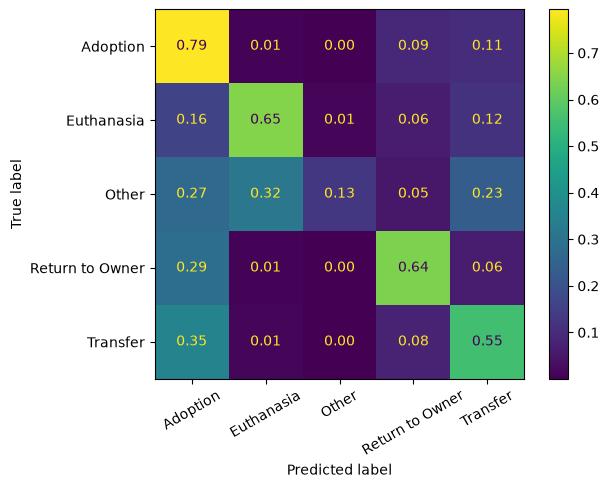

In [3]:
X_dev, X_test = dev[FEATURES], test[FEATURES]
y_dev, y_test = dev["y_outcome"], test["y_outcome"]

clf = Pipeline([("prep", build_preprocessor(columns=FEATURES)),
                ("model", RandomForestClassifier(n_estimators=N_ESTIMATORS, random_state=SEED, n_jobs=-1, **params_clf))])
clf.fit(X_dev, y_dev)
pred = clf.predict(X_test)

baseline = DummyClassifier(strategy="most_frequent").fit(X_dev, y_dev).predict(X_test)
macro_f1 = f1_score(y_test, pred, average="macro")
macro_f1_base = f1_score(y_test, baseline, average="macro")

print(f"macro-F1 en test: {macro_f1:.3f}  (siempre la clase más frecuente: {macro_f1_base:.3f})\n")
print(classification_report(y_test, pred))

ConfusionMatrixDisplay.from_predictions(y_test, pred, normalize="true", xticks_rotation=30, values_format=".2f")
plt.show()

## 2. Regresión

Solo con los adoptados. El R² se mide en log y el error se reporta en días (`np.expm1`).

In [4]:
adopted_dev = dev["y_outcome"] == "Adoption"
adopted_test = test["y_outcome"] == "Adoption"

X_dev_reg, y_dev_reg = dev.loc[adopted_dev, FEATURES], dev.loc[adopted_dev, "y_log_days"]
X_test_reg, y_test_reg = test.loc[adopted_test, FEATURES], test.loc[adopted_test, "y_log_days"]

reg = Pipeline([("prep", build_preprocessor(columns=FEATURES)),
                ("model", RandomForestRegressor(n_estimators=N_ESTIMATORS, random_state=SEED, n_jobs=-1, **params_reg))])
reg.fit(X_dev_reg, y_dev_reg)
pred_log = reg.predict(X_test_reg)

baseline_log = DummyRegressor(strategy="median").fit(X_dev_reg, y_dev_reg).predict(X_test_reg)

r2 = r2_score(y_test_reg, pred_log)
mae = mean_absolute_error(np.expm1(y_test_reg), np.expm1(pred_log))
r2_base = r2_score(y_test_reg, baseline_log)
mae_base = mean_absolute_error(np.expm1(y_test_reg), np.expm1(baseline_log))

pd.DataFrame({"R² (log)": [r2, r2_base], "MAE (días)": [mae, mae_base]},
             index=["Random forest", "Siempre la mediana"]).round(3)

,R² (log),MAE (días)
Random forest,0.412,18.393
Siempre la mediana,-0.051,24.130


## 3. Test frente a validación cruzada

Valores del random forest, experimento 1, de `results/cross-validation-results.md`. Si test sale mucho peor, el modelo se ajustó demasiado a dev.

In [5]:
cv = {"macro-F1": 0.576, "R² (log)": 0.413, "MAE (días)": 18.556}
test_results = {"macro-F1": macro_f1, "R² (log)": r2, "MAE (días)": mae}

comparison = pd.DataFrame({"Validación cruzada": cv, "Test": test_results})
comparison["Diferencia"] = comparison["Test"] - comparison["Validación cruzada"]
comparison.round(3)

,Validación cruzada,Test,Diferencia
macro-F1,0.576,0.578,0.002
R² (log),0.413,0.412,-0.001
MAE (días),18.556,18.393,-0.163


## 4. Guardar

Se guardan comprimidos (`compress=9`) para que cada archivo pese menos de 100 MB, el límite de GitHub. Se leen igual, con `joblib.load`.

In [6]:
joblib.dump(clf, OUT / "model_clf.joblib", compress=9)
joblib.dump(reg, OUT / "model_reg.joblib", compress=9)

504